## <div style="direction:rtl;text-align:right">  بخش دوم: پردازش و بازیابی تصویر سند اسکن شده </div>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

<div style="direction:rtl;text-align:right">

#### سوال اول؛ بارگزاری تصویر و اضافه کردن نویز 
- بارگزاری تصویر
</div>

In [5]:
img = cv2.imread("scanned_document.png", cv2.IMREAD_UNCHANGED)

print("Shape     :", img.shape)
print("Data type :", img.dtype)
print("Min / Max :", img.min(), "/", img.max())

# برای پردازش، تصویر را خاکستری می‌کنیم (اگر از قبل خاکستری باشد، دست نمی‌زنیم)
if img.ndim == 3:
    original = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
else:
    original = img

print("Working image shape:", original.shape)

Shape     : (2048, 2048, 3)
Data type : uint8
Min / Max : 23 / 248
Working image shape: (2048, 2048)


<div style="direction:rtl;text-align:right">

- توابع نویز
</div>

In [6]:
np.random.seed(42)   # برای تکرارپذیر بودن نتایج

def add_salt_pepper(image, amount=0.05):
    """به‌طور تصادفی amount از پیکسل‌ها را سیاه (فلفل) یا سفید (نمک) می‌کند.
    نصف آن‌ها نمک و نصف دیگر فلفل است."""
    noisy = image.copy()
    rand = np.random.rand(*image.shape)      # برای هر پیکسل یک عدد تصادفی بین 0 و 1
    noisy[rand < amount / 2] = 0             # فلفل
    noisy[rand > 1 - amount / 2] = 255       # نمک
    return noisy

def add_gaussian(image, mean=0, sigma=25):
    """به همه پیکسل‌ها یک مقدار تصادفی با توزیع نرمال اضافه می‌کند."""
    noise = np.random.normal(mean, sigma, image.shape)
    noisy = image.astype(np.float32) + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)   # نگه داشتن در بازه 0 تا 255

<div style="direction:rtl;text-align:right">

- ساخت تصاویر نویزدار
</div>

In [7]:
# پارامترها
SP_AMOUNT = 0.05      # چگالی نویز فلفل نمکی: ۵٪
GAUSS_MEAN = 0        # میانگین نویز گاوسی
GAUSS_SIGMA = 25      # انحراف معیار نویز گاوسی

noisy_sp    = add_salt_pepper(original, SP_AMOUNT)
noisy_gauss = add_gaussian(original, GAUSS_MEAN, GAUSS_SIGMA)

print("Salt & Pepper -> amount =", SP_AMOUNT)
print("Gaussian      -> mean =", GAUSS_MEAN, ", sigma =", GAUSS_SIGMA)

Salt & Pepper -> amount = 0.05
Gaussian      -> mean = 0 , sigma = 25


<div style="direction:rtl;text-align:right">

- نمایش تصاویر
</div>

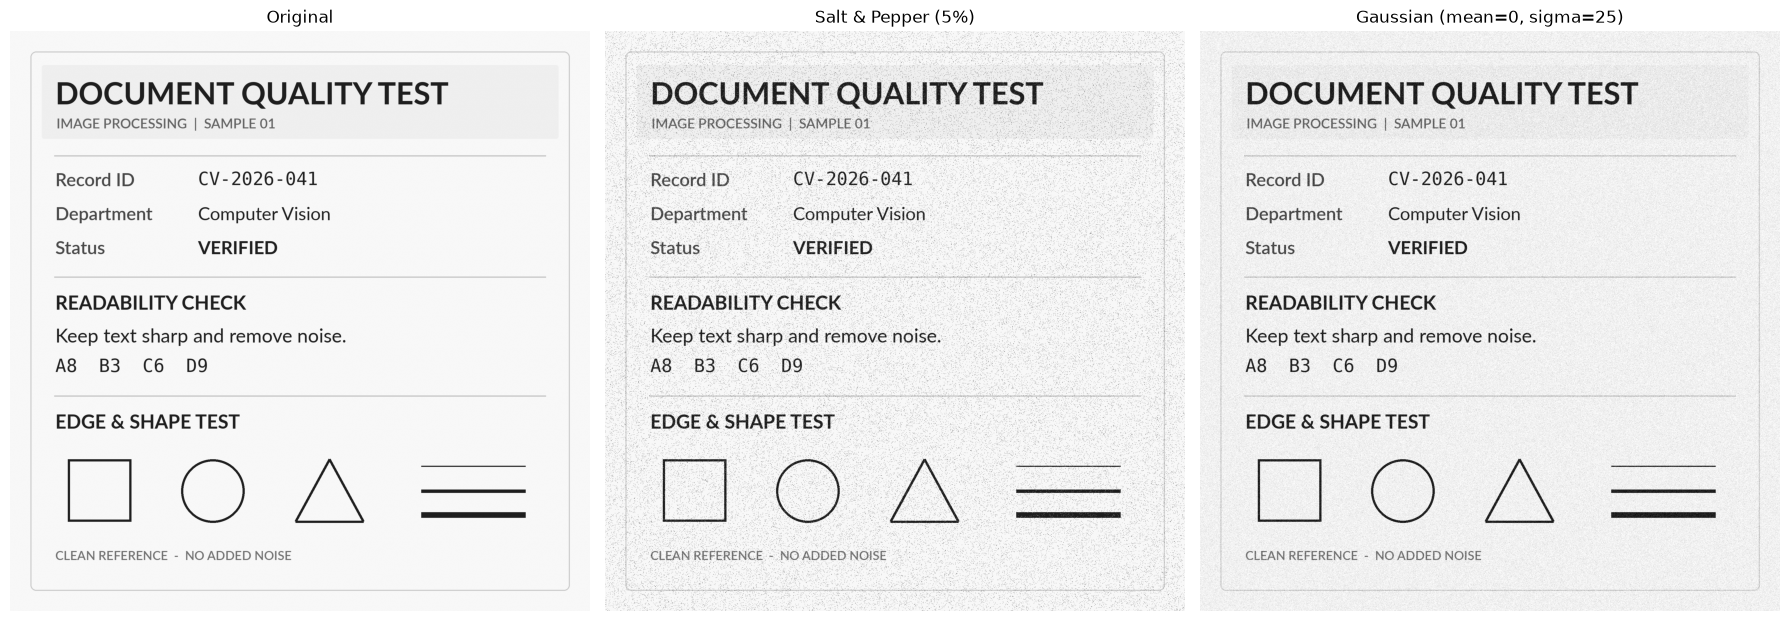

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

axes[0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")

axes[1].imshow(noisy_sp, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Salt & Pepper (5%)")

axes[2].imshow(noisy_gauss, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Gaussian (mean=0, sigma=25)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

<div style="direction:rtl;text-align:right">

- بزرگنمایی عبارت DOCUMENT برای واضح دیده شدن نویزهای تصاویر
</div>

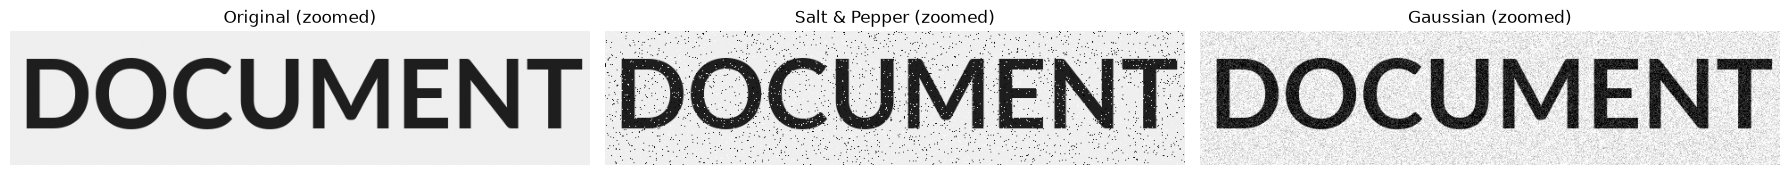

In [15]:
y1, y2, x1, x2 = 150, 300, 150, 800

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(original[y1:y2, x1:x2], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original (zoomed)")

axes[1].imshow(noisy_sp[y1:y2, x1:x2], cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Salt & Pepper (zoomed)")

axes[2].imshow(noisy_gauss[y1:y2, x1:x2], cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Gaussian (zoomed)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

<div style="direction:rtl;text-align:right">

##### نویز فلفل‌نمکی (Salt & Pepper)
- **ماهیت:** نویز ضربه‌ای (Impulse). تعداد کمی از پیکسل‌ها به‌طور کامل با مقدار بیشینه (۲۵۵، نمک) یا کمینه (۰، فلفل) جایگزین می‌شوند و بقیه پیکسل‌ها **دست‌نخورده** می‌مانند.
- **علت در دنیای واقعی:** پیکسل‌های خراب سنسور، خطا در انتقال داده یا گرد و غبار روی اسکنر.
- **پارامتر:** چگالی ۵٪ (نصف نمک، نصف فلفل).

##### نویز گاوسی (Gaussian)
- **ماهیت:** به **همه** پیکسل‌ها یک مقدار تصادفی با توزیع نرمال (گاوسی) اضافه می‌شود. بیشتر مقادیر نویز کوچک‌اند و مقادیر بزرگ کم‌تر پیش می‌آیند.
- **علت در دنیای واقعی:** نویز الکترونیکی سنسور، نور کم و دمای بالای سنسور.
- **پارامترها:** میانگین = ۰ و انحراف معیار (sigma) = ۲۵ (هرچه sigma بزرگ‌تر، نویز شدیدتر).

##### تفاوت‌ها
| ویژگی | فلفل‌نمکی | گاوسی |
|---|---|---|
| پیکسل‌های درگیر | درصد کمی از پیکسل‌ها | همه پیکسل‌ها |
| اندازه خطا | خیلی بزرگ (۰ یا ۲۵۵) | کوچک تا متوسط |
| پیکسل‌های سالم | مقدار اصلی را دقیقاً حفظ می‌کنند | همگی کمی تغییر کرده‌اند |
| ظاهر | نقطه‌های سیاه و سفید پراکنده | دانه‌دانه شدن کل تصویر |
</div>

<div style="direction:rtl;text-align:right">

#### سوال دوم؛ مفهوم کرنل و پیاده‌سازی فیلتر گذاری 

##### کرنل (Kernel) چیست؟
کرنل یک **ماتریس کوچک از وزن‌ها** است (معمولاً با ابعاد فرد مثل ۳×۳، ۵×۵ یا ۷×۷). این ماتریس روی تصویر حرکت می‌کند و تعیین می‌کند هر پیکسل خروجی چگونه از روی پیکسل‌های همسایه‌اش ساخته شود.

##### کاربردها
- **محو کردن (Blur) و کاهش نویز:** کرنل میانگین‌گیر و گاوسی
- **تیز کردن (Sharpening)**
- **استخراج لبه:** Sobel و Laplacian
- و هر عملیات مکانی دیگری که با ترکیب خطی همسایه‌ها قابل بیان باشد.

##### نحوه اعمال کرنل بر تصویر
برای هر پیکسل:
1. مرکز کرنل را روی آن پیکسل قرار می‌دهیم.
2. هر وزن کرنل را در پیکسل متناظرش از تصویر ضرب می‌کنیم.
3. حاصل‌ضرب‌ها را جمع می‌کنیم و نتیجه، مقدار آن پیکسل در تصویر خروجی است.
4. کرنل را به پیکسل بعدی می‌بریم و تکرار می‌کنیم.

> **نکته:** این عملیات از نظر ریاضی «همبستگی» (Correlation) است. در «کانولوشن» کرنل ابتدا ۱۸۰ درجه چرخانده می‌شود. برای کرنل‌های متقارن (Mean، Gaussian، Laplacian) هر دو یکسان‌اند. OpenCV هم در `filter2D` همین همبستگی را انجام می‌دهد و ما هم همان را پیاده می‌کنیم.

##### مدیریت پیکسل‌های مرزی
وقتی کرنل روی پیکسل‌های کنار تصویر قرار می‌گیرد، بخشی از آن بیرون تصویر می‌افتد. برای حل این مشکل به اندازه `k // 2` پیکسل دور تصویر اضافه می‌کنیم (**Padding**) و مقدار آن‌ها را با **انعکاس (Reflect)** پیکسل‌های لبه تصویر پر می‌کنیم. این‌گونه اندازه خروجی با ورودی برابر می‌ماند و لبه‌ها تیره یا مصنوعی نمی‌شوند (مثل Zero Padding که حاشیه سیاه ایجاد می‌کند). این همان روش پیش‌فرض OpenCV هم هست.

- تابع فیلترگذاری
</div>

In [16]:
def apply_filter(image, kernel):
    """فیلترگذاری مکانی یک تصویر خاکستری با کرنلی با هر اندازه فرد.
    خروجی float32 است (برای Sobel و Laplacian مقادیر منفی هم داریم)."""
    kernel = np.array(kernel, dtype=np.float32)
    k_h, k_w = kernel.shape
    pad_h, pad_w = k_h // 2, k_w // 2

    # 1) اضافه کردن حاشیه با انعکاس پیکسل‌های لبه
    padded = np.pad(image.astype(np.float32),
                    ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")

    # 2) ساخت خروجی خالی
    h, w = image.shape
    output = np.zeros((h, w), dtype=np.float32)

    # 3) به ازای هر وزن کرنل، کل تصویر (شیفت‌داده‌شده) را در آن وزن ضرب و جمع می‌کنیم
    for i in range(k_h):
        for j in range(k_w):
            output += kernel[i, j] * padded[i:i + h, j:j + w]

    return output


def to_uint8(image):
    """تبدیل نتیجه فیلتر به تصویر 8 بیتی قابل نمایش"""
    return np.clip(np.round(image), 0, 255).astype(np.uint8)

<div style="direction:rtl;text-align:right">

##### منطق تابع
به‌جای حرکت دادن کرنل روی تک‌تک پیکسل‌ها (که با حلقه‌های تو در توی پایتون بسیار کند است)، از این ایده استفاده کردیم:

برش `padded[i:i+h, j:j+w]` یعنی **کل تصویر به اندازه (i, j) شیفت‌یافته**. مثلاً برای i=0 و j=0 در کرنل ۳×۳، این برش «همسایه بالا-چپ» همه پیکسل‌ها را یکجا می‌دهد. پس کافی است هر وزن کرنل را در برش متناظرش ضرب کنیم و همه را جمع بزنیم. نتیجه دقیقاً همان جمع حاصل‌ضرب‌های کرنل و همسایگی برای تک‌تک پیکسل‌هاست، فقط سریع‌تر.

- با `k_h` و `k_w` هر اندازه کرنل پشتیبانی می‌شود.
- از هیچ تابع آماده فیلترگذاری استفاده نشده است (فقط `np.pad` برای اضافه کردن حاشیه).
</div>

<div style="direction:rtl;text-align:right">

- تست تابع با کرنل‌های مختلف
</div>

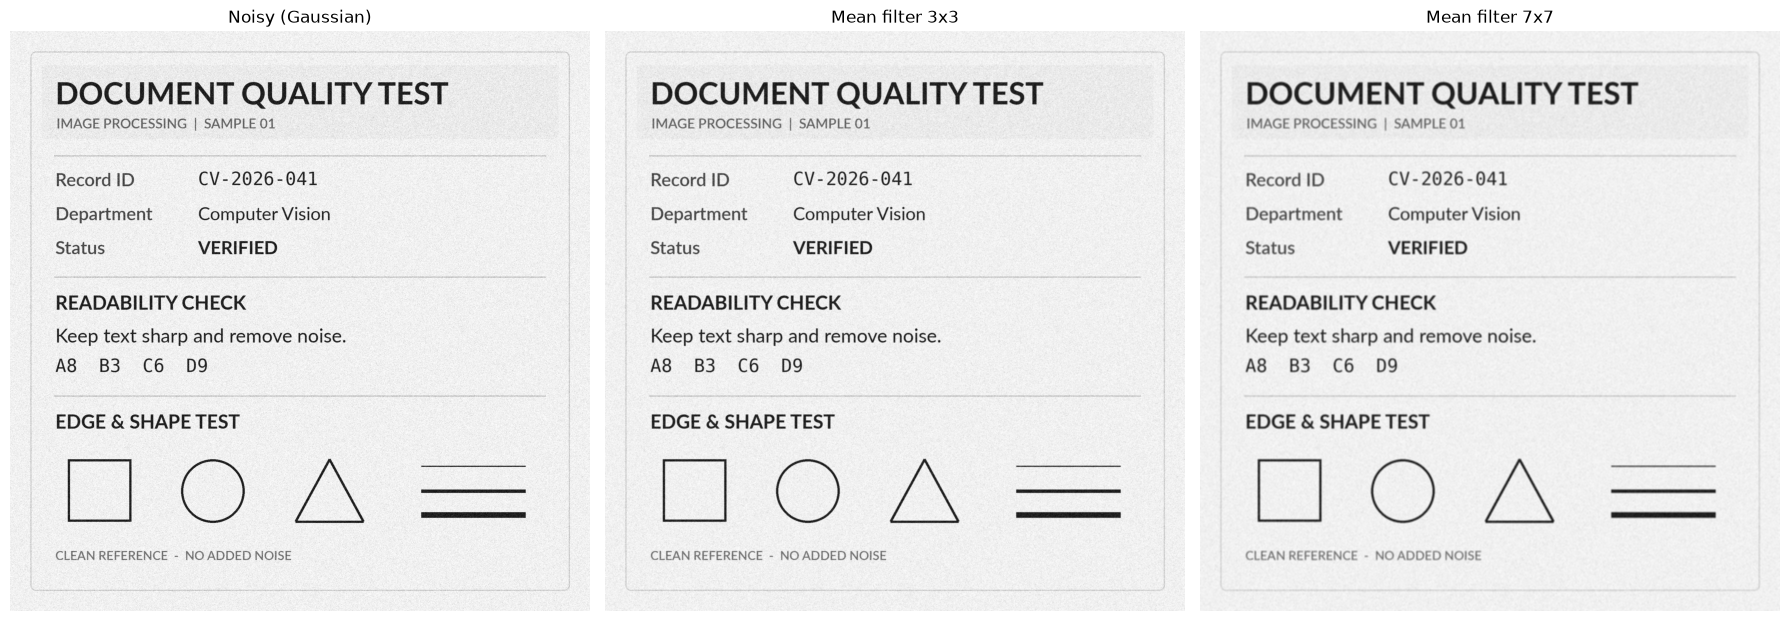

In [18]:
# کرنل میانگین‌گیر با اندازه‌های ۳×۳ و ۷×۷
mean_3 = np.ones((3, 3)) / 9
mean_7 = np.ones((7, 7)) / 49

result_3 = to_uint8(apply_filter(noisy_gauss, mean_3))
result_7 = to_uint8(apply_filter(noisy_gauss, mean_7))

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

axes[0].imshow(noisy_gauss, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Noisy (Gaussian)")

axes[1].imshow(result_3, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Mean filter 3x3")

axes[2].imshow(result_7, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Mean filter 7x7")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

<div style="direction:rtl;text-align:right">

- صحت‌سنجی تابع

جهت اطمینان از درست بودن مقایسه در سوال ۵
</div>

In [20]:
reference = cv2.filter2D(noisy_gauss.astype(np.float32), -1, mean_3.astype(np.float32))
mine = apply_filter(noisy_gauss, mean_3)

print("Max absolute difference with OpenCV:", np.abs(mine - reference).max())

Max absolute difference with OpenCV: 4.5776367e-05


<div style="direction:rtl;text-align:right">

##### نتیجه
- تابع روی کرنل‌های ۳×۳ و ۷×۷ درست کار می‌کند و با افزایش اندازه کرنل، تصویر محوتر می‌شود.
- اختلاف تابع دستی با `cv2.filter2D` تقریباً صفر است (در حد خطای محاسبات اعشاری)، که نشان می‌دهد پیاده‌سازی و مدیریت مرزها درست است.
</div>